# Modélisation des déterminants socio-économiques du vote
## Régression OLS et WLS locale

Notebook structuré en 8 parties, produisant tous les tableaux et figures utilisés dans le rapport :

1. Chargement des données et filtrage métropole
2. Analyse exploratoire (heatmap des corrélations)
3. Régression OLS globale (train / test)
4. Diagnostic de colinéarité (VIF)
5. Distance de Mahalanobis (Ledoit-Wolf) et poids gaussiens
6. Régression WLS locale
7. Diagnostic de l'hétérogénéité des coefficients locaux
8. Tableau comparatif OLS vs WLS




## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.covariance import LedoitWolf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

BASE = "/content/drive/MyDrive/Stage/"
RANDOM_STATE = 42
print("Setup OK")


Mounted at /content/drive
Setup OK


## Partie 1 : Chargement des données et filtrage métropole

Chaque ligne de la base est un bureau de vote, avec ses variables socio-économiques
et ses résultats électoraux. Les DOM-TOM sont exclus (granularité d'agrégation IRIS
trop grossière dans ces territoires, cf. Chapitre 5.1 du mémoire).

In [2]:
df = pd.read_csv(BASE + "base_finale_bureaux.csv", dtype={"id_bv": str})
print(f"Dimensions : {df.shape}")


Dimensions : (68770, 45)


In [3]:
# Filtrage France métropolitaine (exclusion DOM-TOM 971-976, 987-988)
n_avant = len(df)
dep_code = df["id_bv"].astype(str).str.split("_").str[0]
is_dom_tom = dep_code.str.startswith(("97", "98"))

df = df[~is_dom_tom].reset_index(drop=True)

print(f"Bureaux avant filtrage : {n_avant:,}")
print(f"Bureaux DOM-TOM exclus : {is_dom_tom.sum():,}")
print(f"Bureaux après filtrage (métropole) : {len(df):,}  ({100*len(df)/n_avant:.1f}%)")


Bureaux avant filtrage : 68,770
Bureaux DOM-TOM exclus : 2,000
Bureaux après filtrage (métropole) : 66,770  (97.1%)


In [4]:
# Variables explicatives (profil socio-économique) — 8 variables du Chapitre 2
X_COLS = [
    "taux_chomage",    # Taux de chômage (actifs 15-64 ans)
    "part_voiture",    # Part de la voiture parmi les modes de transport
    "part_tcom",       # Part des transports en commun
    "part_diplmin",    # Part sans diplôme
    "part_bac2",       # Part diplômés bac+2
    "part_bac34",      # Part diplômés bac+3/4
    "part_bac5plus",   # Part diplômés bac+5 et plus
    "DISP_MED21",      # Revenu médian par unité de consommation
]

# Variable à prédire : liste explicite des 12 candidats (plus sûr qu'une
# liste noire de colonnes à exclure — évite qu'une colonne parasite,
# ex. un taux de participation, se glisse dans le modèle)
Y_COLS = [
    "ARTHAUD_Nathalie", "DUPONT-AIGNAN_Nicolas", "HIDALGO_Anne", "JADOT_Yannick",
    "LASSALLE_Jean", "LE PEN_Marine", "MACRON_Emmanuel", "MÉLENCHON_Jean-Luc",
    "POUTOU_Philippe", "PÉCRESSE_Valérie", "ROUSSEL_Fabien", "ZEMMOUR_Éric",
]

manquantes = [c for c in Y_COLS if c not in df.columns]
if manquantes:
    raise ValueError(f"Colonnes candidats introuvables dans df : {manquantes}")

NOMS_COURTS = {
    "ARTHAUD_Nathalie": "Arthaud", "DUPONT-AIGNAN_Nicolas": "Dupont-Aignan",
    "HIDALGO_Anne": "Hidalgo", "JADOT_Yannick": "Jadot", "LASSALLE_Jean": "Lassalle",
    "LE PEN_Marine": "Le Pen", "MACRON_Emmanuel": "Macron",
    "MÉLENCHON_Jean-Luc": "Mélenchon", "POUTOU_Philippe": "Poutou",
    "PÉCRESSE_Valérie": "Pécresse", "ROUSSEL_Fabien": "Roussel", "ZEMMOUR_Éric": "Zemmour",
}

# 7 candidats principaux, pour la lisibilité de la heatmap (Partie 2)
Y_PRINCIPAUX = [
    "MACRON_Emmanuel", "LE PEN_Marine", "MÉLENCHON_Jean-Luc", "ZEMMOUR_Éric",
    "PÉCRESSE_Valérie", "JADOT_Yannick", "LASSALLE_Jean",
]

print(f"Variables explicatives : {len(X_COLS)} — {X_COLS}")
print(f"\nCandidats : {len(Y_COLS)}")
for c in Y_COLS:
    print(f"  {c:<25} -> {NOMS_COURTS[c]}")


Variables explicatives : 8 — ['taux_chomage', 'part_voiture', 'part_tcom', 'part_diplmin', 'part_bac2', 'part_bac34', 'part_bac5plus', 'DISP_MED21']

Candidats : 12
  ARTHAUD_Nathalie          -> Arthaud
  DUPONT-AIGNAN_Nicolas     -> Dupont-Aignan
  HIDALGO_Anne              -> Hidalgo
  JADOT_Yannick             -> Jadot
  LASSALLE_Jean             -> Lassalle
  LE PEN_Marine             -> Le Pen
  MACRON_Emmanuel           -> Macron
  MÉLENCHON_Jean-Luc        -> Mélenchon
  POUTOU_Philippe           -> Poutou
  PÉCRESSE_Valérie          -> Pécresse
  ROUSSEL_Fabien            -> Roussel
  ZEMMOUR_Éric              -> Zemmour


In [5]:
# Nettoyage : bureaux avec toutes les variables disponibles
df_clean = df[X_COLS + Y_COLS + ["id_bv"]].dropna().reset_index(drop=True)
print(f"Bureaux après nettoyage : {len(df_clean):,} / {len(df):,}")

X = df_clean[X_COLS].values
y_dict = {col: df_clean[col].values for col in Y_COLS}


Bureaux après nettoyage : 66,770 / 66,770


In [6]:
# Split train (80%) / test (20%) — le test sert uniquement à évaluer les
# modèles finaux (OLS et WLS), jamais à les entraîner ni à les calibrer.
idx_all = np.arange(len(df_clean))
idx_train, idx_test = train_test_split(idx_all, test_size=0.20, random_state=RANDOM_STATE)

X_train_raw, X_test_raw = X[idx_train], X[idx_test]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)   # scaler calibré sur le train uniquement
X_test  = scaler.transform(X_test_raw)

y_train_dict = {col: y_dict[col][idx_train] for col in Y_COLS}
y_test_dict  = {col: y_dict[col][idx_test]  for col in Y_COLS}

print(f"Bureaux train : {len(idx_train):,}   Bureaux test : {len(idx_test):,}")


Bureaux train : 53,416   Bureaux test : 13,354


## Partie 2 : Analyse exploratoire

Heatmap des corrélations entre les 8 variables socio-économiques et les 7 candidats
principaux, calculée sur le train uniquement.

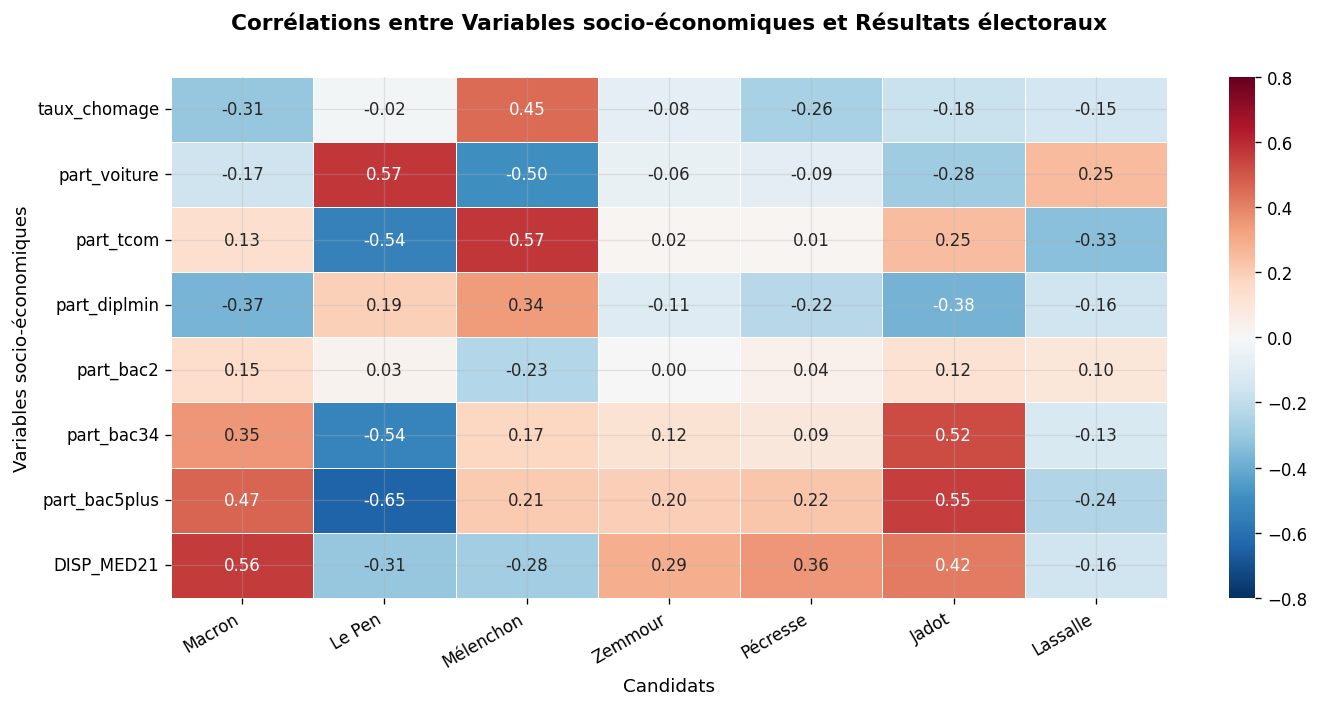

Figure sauvegardee : figure_heatmap_socio_vote.png


In [7]:
df_train_view = df_clean.iloc[idx_train]
corr_matrix = df_train_view[X_COLS + Y_PRINCIPAUX].corr()
corr_socio_vote = corr_matrix.loc[X_COLS, Y_PRINCIPAUX]

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(corr_socio_vote, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-0.8, vmax=0.8, linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Corrélations entre Variables socio-économiques et Résultats électoraux\n",
             fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Candidats", fontsize=11)
ax.set_ylabel("Variables socio-économiques", fontsize=11)
ax.set_xticklabels([NOMS_COURTS[c] for c in Y_PRINCIPAUX], rotation=30, ha="right", fontsize=10)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=10)

plt.tight_layout()
plt.savefig(BASE + "figure_heatmap_socio_vote.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : figure_heatmap_socio_vote.png")


## Partie 3 : Régression OLS globale

Entraînée sur le train, évaluée sur le train (référence) et sur le test (métrique
retenue pour le rapport et pour la comparaison avec le WLS en Partie 6).

In [8]:
resultats_ols = {}

for col in Y_COLS:
    y_tr, y_te = y_train_dict[col], y_test_dict[col]
    model = LinearRegression().fit(X_train, y_tr)
    pred_train, pred_test = model.predict(X_train), model.predict(X_test)

    resultats_ols[col] = {
        "model": model, "pred_test": pred_test,
        "r2_train": r2_score(y_tr, pred_train), "r2_test": r2_score(y_te, pred_test),
        "mae_test": mean_absolute_error(y_te, pred_test),
        "rmse_test": np.sqrt(mean_squared_error(y_te, pred_test)),
        "coefs": dict(zip(X_COLS, model.coef_)),
    }

print(f"{'Candidat':<16} {'R2 train':>10} {'R2 test':>10} {'MAE test':>10} {'RMSE test':>10}")
print("-"*60)
for col, res in sorted(resultats_ols.items(), key=lambda x: -x[1]['r2_test']):
    print(f"  {NOMS_COURTS[col]:<14} {res['r2_train']:>10.3f} {res['r2_test']:>10.3f} "
          f"{res['mae_test']:>10.4f} {res['rmse_test']:>10.4f}")


Candidat           R2 train    R2 test   MAE test  RMSE test
------------------------------------------------------------
  Mélenchon           0.567      0.566     5.0189     6.8203
  Le Pen              0.523      0.514     5.6319     7.2701
  Jadot               0.391      0.386     1.4124     1.9142
  Macron              0.356      0.357     4.6566     6.0272
  Lassalle            0.178      0.176     2.1504     3.4299
  Pécresse            0.180      0.162     1.8510     2.7137
  Dupont-Aignan       0.103      0.102     0.9196     1.4137
  Zemmour             0.109      0.101     2.3129     3.1865
  Hidalgo             0.060      0.054     0.8326     1.2692
  Arthaud             0.048      0.053     0.3968     0.5784
  Roussel             0.048      0.047     1.0876     1.6607
  Poutou              0.027      0.026     0.4807     0.7136


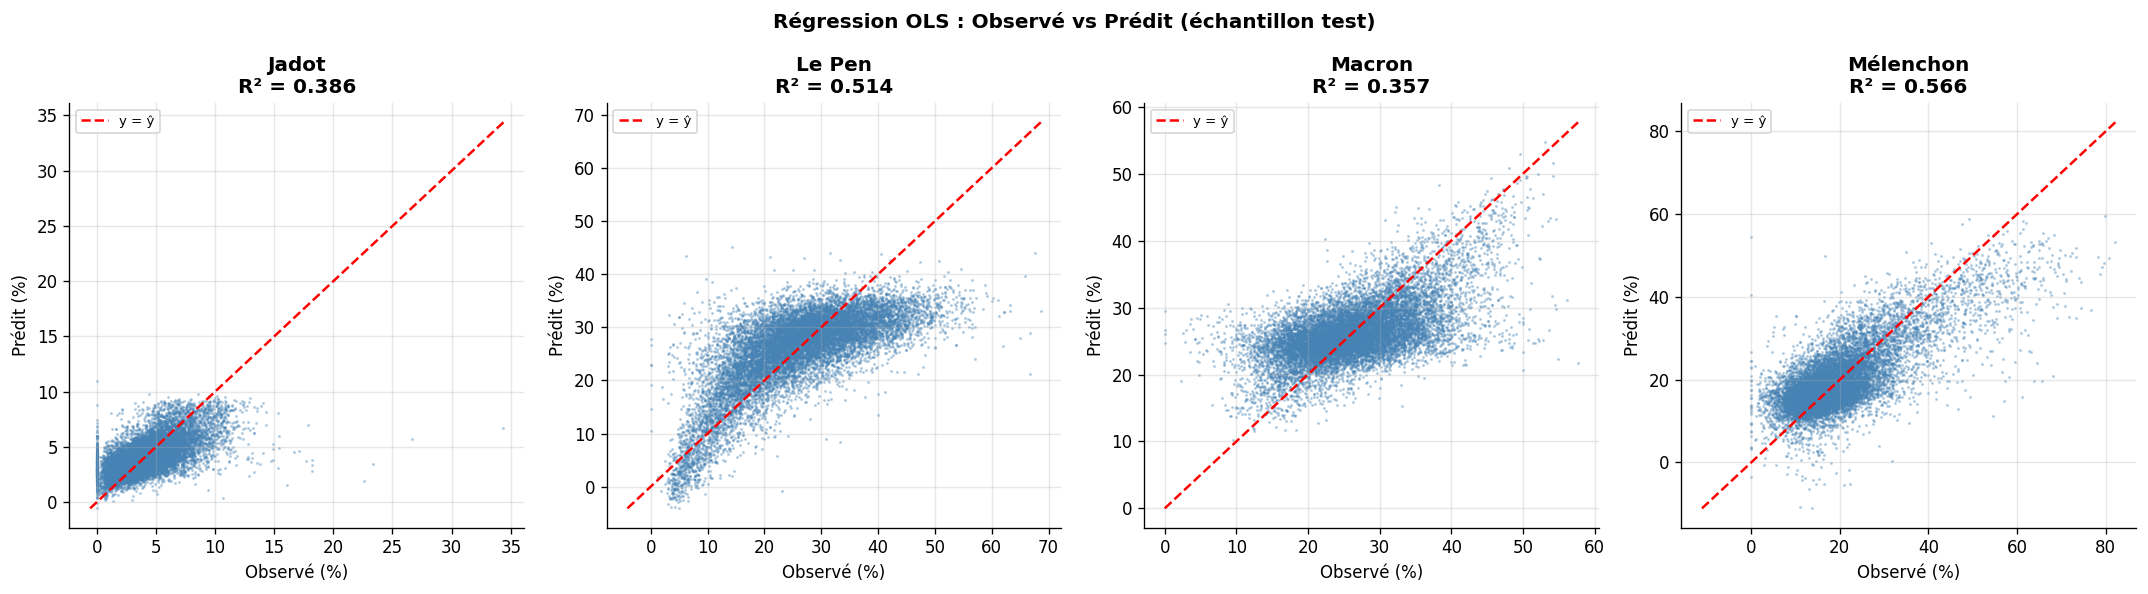

Figure sauvegardee : figure_ols_observed_predicted.png


In [9]:
# Figure : Observé vs Prédit (4 candidats principaux, échantillon test)
cands_fig = ["JADOT_Yannick", "LE PEN_Marine", "MACRON_Emmanuel", "MÉLENCHON_Jean-Luc"]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, cands_fig):
    y_te, y_hat = y_test_dict[col], resultats_ols[col]["pred_test"]
    r2 = resultats_ols[col]["r2_test"]
    ax.scatter(y_te, y_hat, s=0.8, alpha=0.3, color="steelblue")
    lim = [min(y_te.min(), y_hat.min()), max(y_te.max(), y_hat.max())]
    ax.plot(lim, lim, "r--", lw=1.5, label="y = ŷ")
    ax.set_xlabel("Observé (%)", fontsize=10)
    ax.set_ylabel("Prédit (%)", fontsize=10)
    ax.set_title(f"{NOMS_COURTS[col]}\nR² = {r2:.3f}", fontweight="bold")
    ax.legend(fontsize=8)

plt.suptitle("Régression OLS : Observé vs Prédit (échantillon test)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(BASE + "figure_ols_observed_predicted.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : figure_ols_observed_predicted.png")


## Partie 4 : Diagnostic de colinéarité (VIF)

Un VIF > 10 signale une colinéarité problématique pour l'interprétation individuelle
des coefficients (le R² global et les prédictions restent valides quel que soit le VIF).

In [10]:
def compute_vif(X_mat, col_names):
    vifs = []
    for j in range(X_mat.shape[1]):
        y_j = X_mat[:, j]
        X_others = np.delete(X_mat, j, axis=1)
        r2_j = r2_score(y_j, LinearRegression().fit(X_others, y_j).predict(X_others))
        vifs.append(np.inf if r2_j >= 1 else 1 / (1 - r2_j))
    return pd.DataFrame({"variable": col_names, "VIF": vifs}).sort_values("VIF", ascending=False)

vif_table = compute_vif(X_train, X_COLS)
print("VIF (calculés sur le train) :")
print(vif_table.to_string(index=False))


VIF (calculés sur le train) :
     variable      VIF
part_bac5plus 5.112847
 part_voiture 4.822143
    part_tcom 4.456509
   DISP_MED21 2.923917
 part_diplmin 2.506303
 taux_chomage 1.950620
   part_bac34 1.809207
    part_bac2 1.532104


## Partie 5 : Distance de Mahalanobis et poids gaussiens



In [11]:
lw = LedoitWolf().fit(X_train)
cov_inv = np.linalg.inv(lw.covariance_)

cond_emp = np.linalg.cond(np.cov(X_train.T))
cond_lw  = np.linalg.cond(lw.covariance_)
print(f"Condition number — empirique : {cond_emp:.1f}")
print(f"Condition number — LedoitWolf : {cond_lw:.1f}")
print(f"Coefficient de shrinkage : {lw.shrinkage_:.4f}")


Condition number — empirique : 26.5
Condition number — LedoitWolf : 26.4
Coefficient de shrinkage : 0.0003


In [12]:
# Distances de Mahalanobis — échantillon descriptif (train)
N_SAMPLE = 4000
np.random.seed(RANDOM_STATE)
idx_desc = np.random.choice(len(X_train), N_SAMPLE, replace=False)
X_desc = X_train[idx_desc]

diff = X_desc[:, None, :] - X_desc[None, :, :]
D_maha = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff, cov_inv, diff))
D_euclid = np.sqrt((diff**2).sum(axis=2))
sigma = np.median(D_maha[D_maha > 0])

print(f"Distance de Mahalanobis : median={sigma:.3f}  max={D_maha.max():.3f}")
print(f"Distance Euclidienne    : median={np.median(D_euclid[D_euclid>0]):.3f}")


Distance de Mahalanobis : median=3.363  max=32.180
Distance Euclidienne    : median=3.115


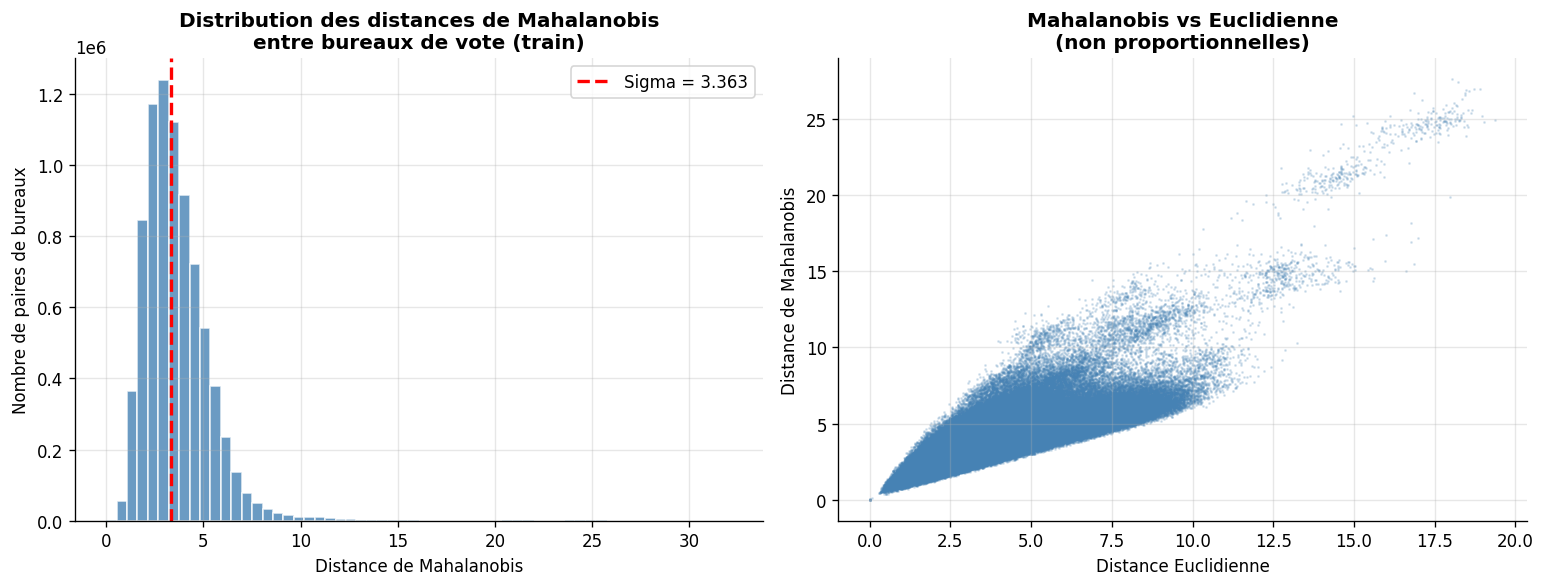

Figure sauvegardee : figure_distances_mahalanobis.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

d_flat = D_maha[np.triu_indices(N_SAMPLE, k=1)]
axes[0].hist(d_flat, bins=60, color="steelblue", alpha=0.8, edgecolor="white")
axes[0].axvline(sigma, color="red", linestyle="--", lw=2, label=f"Sigma = {sigma:.3f}")
axes[0].set_xlabel("Distance de Mahalanobis"); axes[0].set_ylabel("Nombre de paires de bureaux")
axes[0].set_title("Distribution des distances de Mahalanobis\nentre bureaux de vote (train)", fontweight="bold")
axes[0].legend()

d_euclid_flat = D_euclid[np.triu_indices(N_SAMPLE, k=1)]
axes[1].scatter(d_euclid_flat[::20], d_flat[::20], s=0.5, alpha=0.2, color="steelblue")
axes[1].set_xlabel("Distance Euclidienne"); axes[1].set_ylabel("Distance de Mahalanobis")
axes[1].set_title("Mahalanobis vs Euclidienne\n(non proportionnelles)", fontweight="bold")

plt.tight_layout()
plt.savefig(BASE + "figure_distances_mahalanobis.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : figure_distances_mahalanobis.png")


Poids moyen (hors diagonale) : 0.5749
Poids > 0.5 : 64.7%   Poids < 0.01 : 0.8%


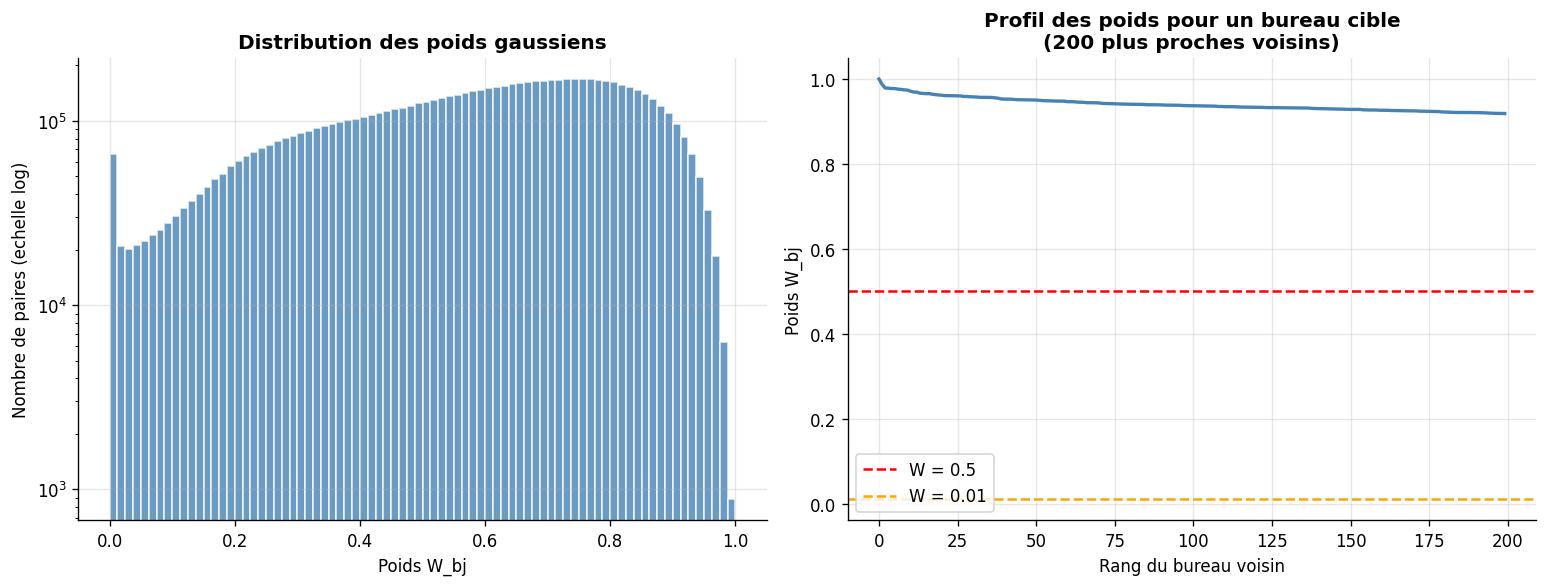

Figure sauvegardee : figure_poids_gaussiens.png


In [14]:
# Poids gaussiens : W_bj = exp(-d(b,j)^2 / 2 sigma^2)  — à titre descriptif
W_desc = np.exp(-D_maha**2 / (2 * sigma**2))
w_off = W_desc[np.triu_indices(N_SAMPLE, k=1)]
print(f"Poids moyen (hors diagonale) : {w_off.mean():.4f}")
print(f"Poids > 0.5 : {(w_off>0.5).mean()*100:.1f}%   Poids < 0.01 : {(w_off<0.01).mean()*100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(w_off, bins=80, color="steelblue", alpha=0.8, edgecolor="white", log=True)
axes[0].set_xlabel("Poids W_bj"); axes[0].set_ylabel("Nombre de paires (echelle log)")
axes[0].set_title("Distribution des poids gaussiens", fontweight="bold")

w_exemple = np.sort(W_desc[0])[::-1][:200]
axes[1].plot(range(len(w_exemple)), w_exemple, color="steelblue", lw=2)
axes[1].axhline(0.5, color="red", ls="--", lw=1.5, label="W = 0.5")
axes[1].axhline(0.01, color="orange", ls="--", lw=1.5, label="W = 0.01")
axes[1].set_xlabel("Rang du bureau voisin"); axes[1].set_ylabel("Poids W_bj")
axes[1].set_title("Profil des poids pour un bureau cible\n(200 plus proches voisins)", fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig(BASE + "figure_poids_gaussiens.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : figure_poids_gaussiens.png")


## Partie 6 : Régression WLS locale

Les bureaux **cibles** proviennent du **test**, le **voisinage** (pool utilisé pour
estimer chaque régression locale) provient exclusivement du **train** : un bureau
cible ne peut jamais apparaître dans sa propre régression. Le MAE/RMSE de l'OLS
utilisé pour le calcul du gain est recalculé sur ces mêmes bureaux cibles, pour une
comparaison strictement équitable.

In [15]:
N_TARGET, POOL_SIZE = 1500, 6000
np.random.seed(RANDOM_STATE)
idx_target = np.random.choice(len(X_test), min(N_TARGET, len(X_test)), replace=False)
idx_pool   = np.random.choice(len(X_train), min(POOL_SIZE, len(X_train)), replace=False)

X_target, X_pool = X_test[idx_target], X_train[idx_pool]

diff_tp = X_target[:, None, :] - X_pool[None, :, :]
D_tp = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff_tp, cov_inv, diff_tp))
W_tp = np.exp(-D_tp**2 / (2 * sigma**2))

print(f"Cibles (test) : {len(X_target):,}   Pool de voisins (train) : {len(X_pool):,}")


Cibles (test) : 1,500   Pool de voisins (train) : 6,000


In [16]:
n_vars = X_pool.shape[1]
resultats_wls = {}
y_pool_dict   = {col: y_train_dict[col][idx_pool]  for col in Y_COLS}
y_target_dict = {col: y_test_dict[col][idx_target] for col in Y_COLS}

print(f"{'Candidat':<16} {'MAE OLS':>10} {'MAE WLS':>10} {'Gain %':>8}")
print("-"*48)

for col in Y_COLS:
    y_pool, y_target = y_pool_dict[col], y_target_dict[col]
    preds = np.full(len(X_target), np.nan)
    betas_locaux = np.full((len(X_target), n_vars), np.nan)

    for i in range(len(X_target)):
        try:
            m = LinearRegression().fit(X_pool, y_pool, sample_weight=W_tp[i])
            preds[i] = m.predict(X_target[[i]])[0]
            betas_locaux[i] = m.coef_
        except Exception:
            pass

    ok = ~np.isnan(preds)
    mae_wls  = mean_absolute_error(y_target[ok], preds[ok])
    rmse_wls = np.sqrt(mean_squared_error(y_target[ok], preds[ok]))
    r2_wls   = r2_score(y_target[ok], preds[ok])

    pred_ols_target = resultats_ols[col]["model"].predict(X_target)
    mae_ols_target  = mean_absolute_error(y_target, pred_ols_target)
    rmse_ols_target = np.sqrt(mean_squared_error(y_target, pred_ols_target))
    r2_ols_target   = r2_score(y_target, pred_ols_target)

    gain = (mae_ols_target - mae_wls) / mae_ols_target * 100
    resultats_wls[col] = {
        "preds": preds, "betas": betas_locaux, "mae": mae_wls, "rmse": rmse_wls, "r2": r2_wls,
        "mae_ols_target": mae_ols_target, "rmse_ols_target": rmse_ols_target, "r2_ols_target": r2_ols_target,
    }
    print(f"  {NOMS_COURTS[col]:<14} {mae_ols_target:>10.4f} {mae_wls:>10.4f} {gain:>+8.1f}%")


Candidat            MAE OLS    MAE WLS   Gain %
------------------------------------------------
  Arthaud            0.3878     0.3889     -0.3%
  Dupont-Aignan      0.9206     0.9290     -0.9%
  Hidalgo            0.8513     0.8459     +0.6%
  Jadot              1.4282     1.4110     +1.2%
  Lassalle           2.1232     2.0370     +4.1%
  Le Pen             5.9001     5.6831     +3.7%
  Macron             4.6589     4.6109     +1.0%
  Mélenchon          5.1135     4.9316     +3.6%
  Poutou             0.4791     0.4773     +0.4%
  Pécresse           1.8843     1.8536     +1.6%
  Roussel            1.0629     1.0596     +0.3%
  Zemmour            2.1929     2.1873     +0.3%


## Partie 7 : Hétérogénéité des coefficients locaux

Un gain de MAE ne suffit pas à prouver que le WLS capture une vraie variation locale.
On compare la dispersion des coefficients locaux β̂_b à l'incertitude d'estimation du
coefficient OLS global : un ratio > 1 signale une variation réelle, pas du bruit.

In [17]:
def ols_standard_errors(X_mat, y_vec, intercept, beta):
    n, p = X_mat.shape
    X_design = np.column_stack([np.ones(n), X_mat])
    y_hat = X_design @ np.concatenate([[intercept], beta])
    sigma2 = ((y_vec - y_hat)**2).sum() / (n - p - 1)
    XtX_inv = np.linalg.inv(X_design.T @ X_design)
    return np.sqrt(np.diag(XtX_inv) * sigma2)[1:]

for col in ["MACRON_Emmanuel", "LE PEN_Marine", "MÉLENCHON_Jean-Luc"]:
    model_ols = resultats_ols[col]["model"]
    se_ols = ols_standard_errors(X_train, y_train_dict[col], model_ols.intercept_, model_ols.coef_)
    betas_locaux = resultats_wls[col]["betas"]

    print(f"\n{NOMS_COURTS[col]}")
    print(f"{'Variable':<16} {'beta_OLS':>10} {'SE_OLS':>10} {'std_WLS':>10} {'ratio':>8}")
    for j, var in enumerate(X_COLS):
        betas_j = betas_locaux[:, j]
        betas_j = betas_j[~np.isnan(betas_j)]
        std_j = betas_j.std()
        ratio = std_j / se_ols[j] if se_ols[j] > 0 else np.nan
        print(f"{var:<16} {model_ols.coef_[j]:>+10.3f} {se_ols[j]:>10.3f} {std_j:>10.3f} {ratio:>8.2f}")



Macron
Variable           beta_OLS     SE_OLS    std_WLS    ratio
taux_chomage         -0.558      0.037      0.096     2.61
part_voiture         -1.383      0.058      0.260     4.50
part_tcom            -1.716      0.056      0.169     3.05
part_diplmin         +0.002      0.042      0.118     2.84
part_bac2            +0.541      0.033      0.103     3.17
part_bac34           +0.238      0.035      0.116     3.27
part_bac5plus        +1.787      0.059      0.255     4.29
DISP_MED21           +2.722      0.045      0.244     5.43

Le Pen
Variable           beta_OLS     SE_OLS    std_WLS    ratio
taux_chomage         -0.215      0.044      0.142     3.25
part_voiture         +2.263      0.069      0.221     3.21
part_tcom            -0.780      0.066      0.278     4.21
part_diplmin         +0.130      0.050      0.326     6.59
part_bac2            -1.218      0.039      0.098     2.53
part_bac34           -2.544      0.042      0.099     2.35
part_bac5plus        -4.504      0.071  

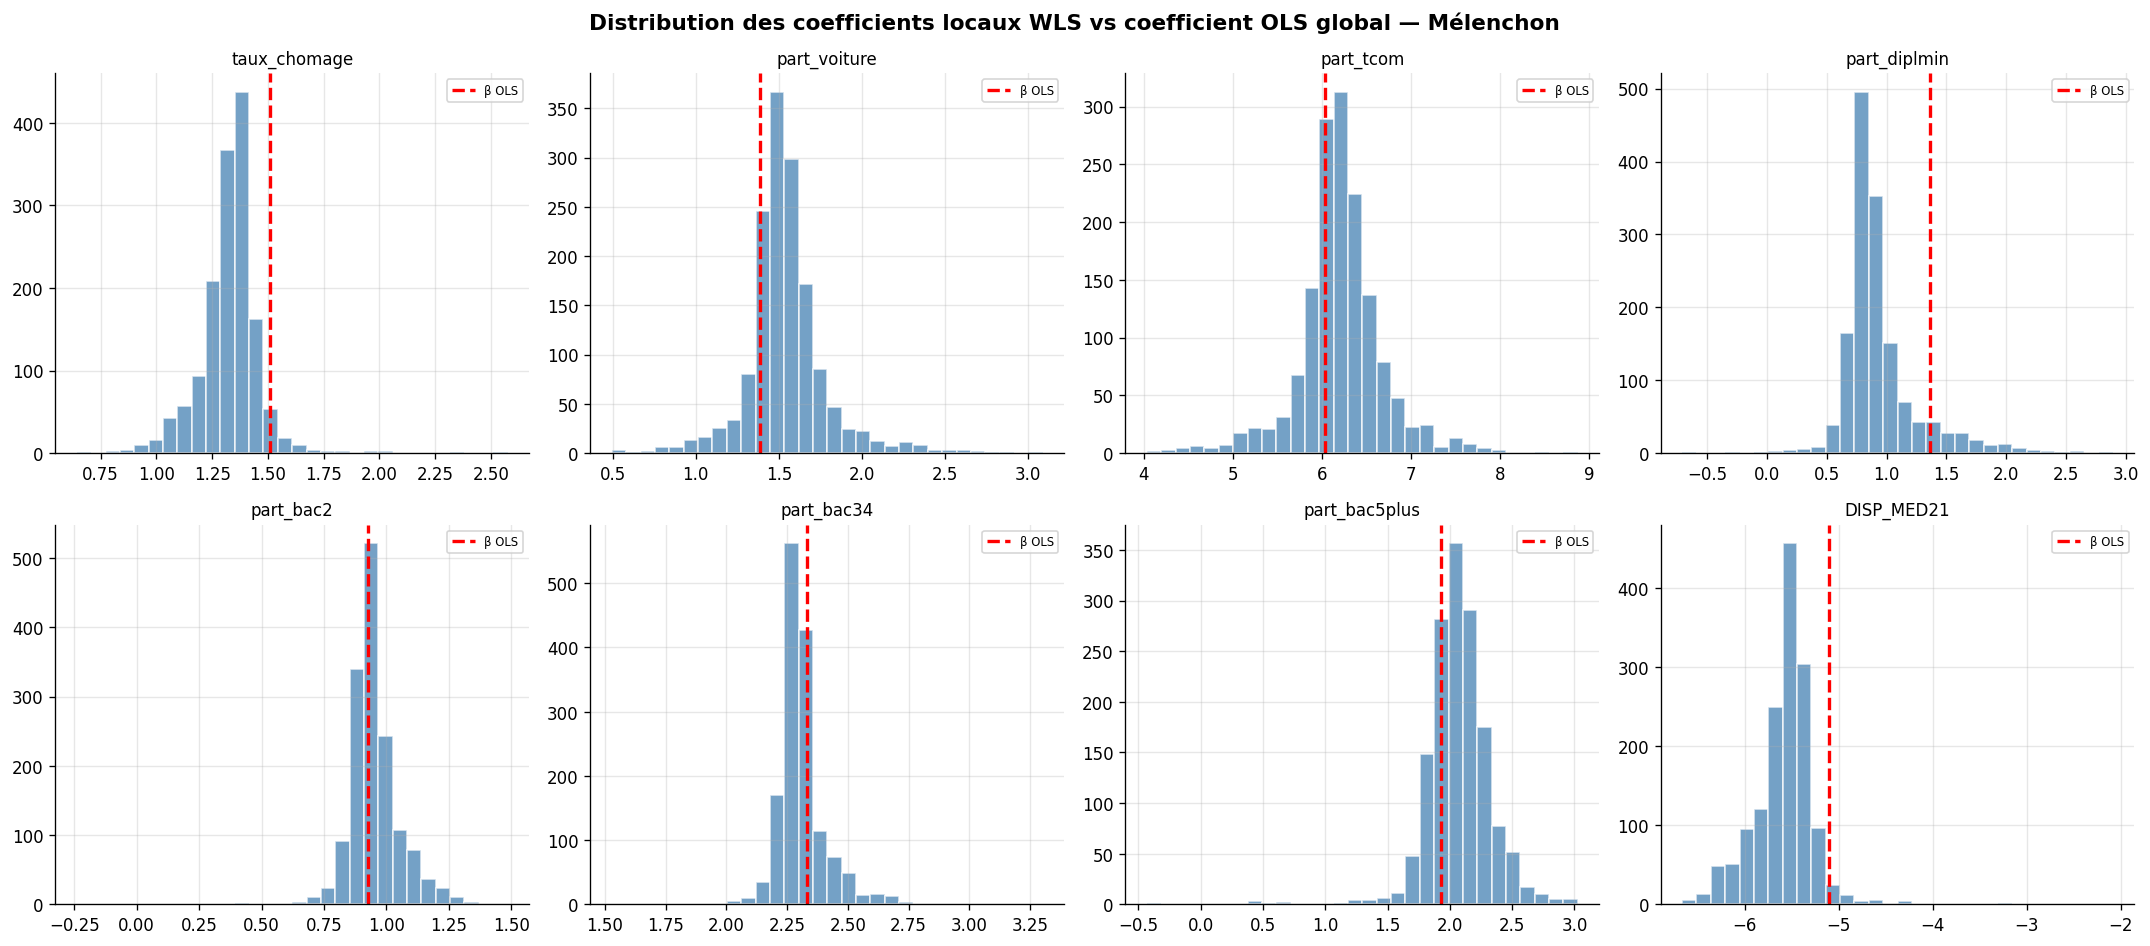

Figure sauvegardee : figure_dispersion_beta_wls.png


In [18]:
# Figure : distribution des coefficients locaux vs coefficient OLS (Mélenchon)
col_ex = "MÉLENCHON_Jean-Luc"
betas_locaux = resultats_wls[col_ex]["betas"]
model_ols = resultats_ols[col_ex]["model"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, var in enumerate(X_COLS):
    ax = axes.flat[j]
    betas_j = betas_locaux[:, j]
    betas_j = betas_j[~np.isnan(betas_j)]
    ax.hist(betas_j, bins=30, color="steelblue", alpha=0.75, edgecolor="white")
    ax.axvline(model_ols.coef_[j], color="red", linestyle="--", lw=2, label="β OLS")
    ax.set_title(var, fontsize=10)
    ax.legend(fontsize=7)
plt.suptitle(f"Distribution des coefficients locaux WLS vs coefficient OLS global — {NOMS_COURTS[col_ex]}",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(BASE + "figure_dispersion_beta_wls.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : figure_dispersion_beta_wls.png")


## Partie 8 : Tableau comparatif OLS vs WLS

Évaluation strictement out-of-sample, comparaison équitable sur le même échantillon test.

In [19]:
rows = []
for col in Y_COLS:
    wls = resultats_wls[col]
    mae_ols, rmse_ols = wls["mae_ols_target"], wls["rmse_ols_target"]
    gain_mae  = (mae_ols  - wls["mae"])  / mae_ols  * 100
    gain_rmse = (rmse_ols - wls["rmse"]) / rmse_ols * 100
    rows.append({
        "Candidat": NOMS_COURTS[col], "R2 OLS": round(wls["r2_ols_target"], 3),
        "MAE OLS": round(mae_ols, 4), "RMSE OLS": round(rmse_ols, 4),
        "MAE WLS": round(wls["mae"], 4), "RMSE WLS": round(wls["rmse"], 4),
        "Gain MAE %": round(gain_mae, 1), "Gain RMSE %": round(gain_rmse, 1),
    })

df_comp = pd.DataFrame(rows).sort_values("Gain MAE %", ascending=False)
print("TABLEAU COMPARATIF OLS vs WLS JENSEN — ÉVALUATION OUT-OF-SAMPLE")
print("="*90)
print(df_comp.to_string(index=False))

df_comp.to_csv(BASE + "tableau_comparatif_ols_wls.csv", index=False)
print("\nExporte : tableau_comparatif_ols_wls.csv")


TABLEAU COMPARATIF OLS vs WLS JENSEN — ÉVALUATION OUT-OF-SAMPLE
     Candidat  R2 OLS  MAE OLS  RMSE OLS  MAE WLS  RMSE WLS  Gain MAE %  Gain RMSE %
     Lassalle   0.184   2.1232    3.2877   2.0370    3.1599         4.1          3.9
       Le Pen   0.519   5.9001    7.5151   5.6831    7.2740         3.7          3.2
    Mélenchon   0.596   5.1135    7.0209   4.9316    6.7348         3.6          4.1
     Pécresse   0.193   1.8843    2.6965   1.8536    2.6563         1.6          1.5
        Jadot   0.408   1.4282    1.9535   1.4110    1.9394         1.2          0.7
       Macron   0.391   4.6589    6.0700   4.6109    6.0578         1.0          0.2
      Hidalgo   0.055   0.8513    1.4485   0.8459    1.4553         0.6         -0.5
       Poutou   0.022   0.4791    0.7280   0.4773    0.7291         0.4         -0.2
      Roussel   0.059   1.0629    1.5922   1.0596    1.5862         0.3          0.4
      Zemmour   0.108   2.1929    2.9527   2.1873    3.0041         0.3         -1.7
 

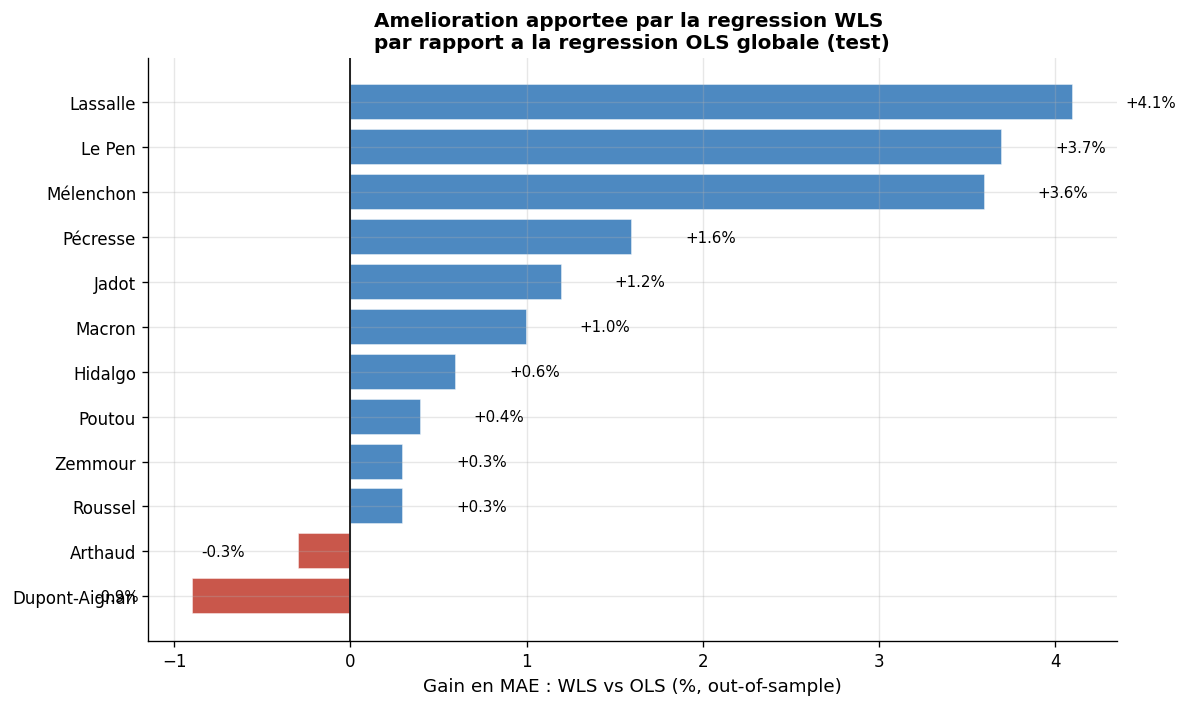

Figure sauvegardee : figure_gain_ols_vs_wls.png


In [20]:
df_fig = df_comp.sort_values("Gain MAE %", ascending=True)
colors = ["#2e75b6" if g > 0 else "#c0392b" for g in df_fig["Gain MAE %"]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df_fig["Candidat"], df_fig["Gain MAE %"], color=colors, alpha=0.85, edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Gain en MAE : WLS vs OLS (%, out-of-sample)", fontsize=11)
ax.set_title("Amelioration apportee par la regression WLS \npar rapport a la regression OLS globale (test)",
             fontsize=12, fontweight="bold")
for bar, val in zip(bars, df_fig["Gain MAE %"]):
    ax.text(val + 0.3 if val >= 0 else val - 0.3, bar.get_y() + bar.get_height()/2,
            f"{val:+.1f}%", va="center", ha="left" if val >= 0 else "right", fontsize=9)

plt.tight_layout()
plt.savefig(BASE + "figure_gain_ols_vs_wls.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardee : figure_gain_ols_vs_wls.png")


In [21]:
#  Prédiction OLS vs WLS pour le bureau 69381_109
ID_BUREAU = "69_029_0011"

idx_bureau = df_clean[df_clean["id_bv"] == ID_BUREAU].index
if len(idx_bureau) == 0:
    raise ValueError(f"Bureau {ID_BUREAU} introuvable dans df_clean "
                      "(a-t-il été exclu au nettoyage, valeurs manquantes ?)")
idx_bureau = idx_bureau[0]

# Récupération du profil socio-économique (normalisé avec le même scaler que le train)
x_brut_bron = df_clean.loc[[idx_bureau], X_COLS].values
x_scaled_bron = scaler.transform(x_brut_bron)

# Le bureau est-il dans le train ou dans le test ?
dans_train = idx_bureau in idx_train
print(f"Bureau {ID_BUREAU} — présent dans l'ensemble : "
      f"{'train' if dans_train else 'test'}\n")

print("Profil socio-économique :")
for var, val in zip(X_COLS, x_brut_bron[0]):
    print(f"  {var:<16} : {val:.4f}")

# ── Pool de voisins pour le WLS : on réutilise X_pool (Partie 6), ──
# en retirant ce bureau du pool s'il s'y trouve déjà (évite l'auto-inclusion)
if dans_train:
    pos_dans_pool = np.where(idx_pool == idx_bureau)[0]
else:
    pos_dans_pool = np.array([], dtype=int)

mask_pool = np.ones(len(X_pool), dtype=bool)
mask_pool[pos_dans_pool] = False
X_pool_bureau_bron = X_pool[mask_pool]

# Distance de Mahalanobis entre ce bureau et le pool de voisins
diff_b = x_scaled_bron[:, None, :] - X_pool_bureau_bron[None, :, :]
D_b_bron = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff_b, cov_inv, diff_b))[0]
W_b_bron = np.exp(-D_b_bron**2 / (2 * sigma**2))

print(f"\n{'Candidat':<14} {'Observé':>10} {'Prédit OLS':>12} {'Prédit WLS':>12} "
      f"{'Ecart OLS':>10} {'Ecart WLS':>10}")
print("-"*72)

for col in Y_COLS:
    observe = df_clean.loc[idx_bureau, col]
    pred_ols = resultats_ols[col]["model"].predict(x_scaled_bron)[0]

    y_pool_bureau_bron = (y_train_dict[col][idx_pool] if not dans_train
                      else y_train_dict[col][idx_pool])[mask_pool]
    m = LinearRegression().fit(X_pool_bureau_bron, y_pool_bureau_bron, sample_weight=W_b_bron)
    pred_wls = m.predict(x_scaled_bron)[0]

    print(f"  {NOMS_COURTS[col]:<12} {observe:>10.2f} {pred_ols:>12.2f} {pred_wls:>12.2f} "
          f"{abs(observe-pred_ols):>10.2f} {abs(observe-pred_wls):>10.2f}")

Bureau 69_029_0011 — présent dans l'ensemble : train

Profil socio-économique :
  taux_chomage     : 0.1526
  part_voiture     : 0.6282
  part_tcom        : 0.2324
  part_diplmin     : 0.1836
  part_bac2        : 0.1160
  part_bac34       : 0.1253
  part_bac5plus    : 0.1452
  DISP_MED21       : 18810.1193

Candidat          Observé   Prédit OLS   Prédit WLS  Ecart OLS  Ecart WLS
------------------------------------------------------------------------
  Arthaud            0.94         0.58         0.55       0.36       0.39
  Dupont-Aignan       1.07         1.55         1.50       0.48       0.43
  Hidalgo            1.87         1.65         1.61       0.22       0.26
  Jadot              4.95         3.87         3.78       1.08       1.17
  Lassalle           1.60         2.23         2.40       0.63       0.80
  Le Pen            14.17        21.14        21.06       6.97       6.89
  Macron            24.73        22.02        21.11       2.71       3.62
  Mélenchon         39.71

In [22]:
#  Prédiction OLS vs WLS pour le bureau 69381_109
ID_BUREAU = "69_123_0109"

idx_bureau = df_clean[df_clean["id_bv"] == ID_BUREAU].index
if len(idx_bureau) == 0:
    raise ValueError(f"Bureau {ID_BUREAU} introuvable dans df_clean "
                      "(a-t-il été exclu au nettoyage, valeurs manquantes ?)")
idx_bureau = idx_bureau[0]

# Récupération du profil socio-économique (normalisé avec le même scaler que le train)
x_brut = df_clean.loc[[idx_bureau], X_COLS].values
x_scaled = scaler.transform(x_brut)

# Le bureau est-il dans le train ou dans le test ?
dans_train = idx_bureau in idx_train
print(f"Bureau {ID_BUREAU} — présent dans l'ensemble : "
      f"{'train' if dans_train else 'test'}\n")

print("Profil socio-économique :")
for var, val in zip(X_COLS, x_brut[0]):
    print(f"  {var:<16} : {val:.4f}")

# ── Pool de voisins pour le WLS : on réutilise X_pool (Partie 6), ──
# en retirant ce bureau du pool s'il s'y trouve déjà (évite l'auto-inclusion)
if dans_train:
    pos_dans_pool = np.where(idx_pool == idx_bureau)[0]
else:
    pos_dans_pool = np.array([], dtype=int)

mask_pool = np.ones(len(X_pool), dtype=bool)
mask_pool[pos_dans_pool] = False
X_pool_bureau = X_pool[mask_pool]

# Distance de Mahalanobis entre ce bureau et le pool de voisins
diff_b = x_scaled[:, None, :] - X_pool_bureau[None, :, :]
D_b = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff_b, cov_inv, diff_b))[0]
W_b = np.exp(-D_b**2 / (2 * sigma**2))

print(f"\n{'Candidat':<14} {'Observé':>10} {'Prédit OLS':>12} {'Prédit WLS':>12} "
      f"{'Ecart OLS':>10} {'Ecart WLS':>10}")
print("-"*72)

for col in Y_COLS:
    observe = df_clean.loc[idx_bureau, col]
    pred_ols = resultats_ols[col]["model"].predict(x_scaled)[0]

    y_pool_bureau = (y_train_dict[col][idx_pool] if not dans_train
                      else y_train_dict[col][idx_pool])[mask_pool]
    m = LinearRegression().fit(X_pool_bureau, y_pool_bureau, sample_weight=W_b)
    pred_wls = m.predict(x_scaled)[0]

    print(f"  {NOMS_COURTS[col]:<12} {observe:>10.2f} {pred_ols:>12.2f} {pred_wls:>12.2f} "
          f"{abs(observe-pred_ols):>10.2f} {abs(observe-pred_wls):>10.2f}")

Bureau 69_123_0109 — présent dans l'ensemble : train

Profil socio-économique :
  taux_chomage     : 0.1380
  part_voiture     : 0.1178
  part_tcom        : 0.4559
  part_diplmin     : 0.0455
  part_bac2        : 0.1123
  part_bac34       : 0.1909
  part_bac5plus    : 0.4366
  DISP_MED21       : 23289.1723

Candidat          Observé   Prédit OLS   Prédit WLS  Ecart OLS  Ecart WLS
------------------------------------------------------------------------
  Arthaud            0.12         0.28         0.28       0.16       0.16
  Dupont-Aignan       0.49         0.62         0.76       0.13       0.27
  Hidalgo            2.10         2.46         2.60       0.36       0.50
  Jadot              9.89         8.20         8.74       1.69       1.15
  Lassalle           1.11         2.66         2.53       1.55       1.42
  Le Pen             5.07        -0.51         0.24       5.58       4.83
  Macron            21.63        31.30        29.48       9.67       7.85
  Mélenchon         51.05

In [23]:
#  préparation du bureau de Bron (profil, pool, poids)
ID_BUREAU_BRON = "69_029_0011"
idx_bureau_bron = df_clean[df_clean["id_bv"] == ID_BUREAU_BRON].index[0]
dans_train_bron = idx_bureau_bron in idx_train

x_brut_bron = df_clean.loc[[idx_bureau_bron], X_COLS].values
x_scaled_bron = scaler.transform(x_brut_bron)

pos_dans_pool_bron = np.where(idx_pool == idx_bureau_bron)[0] if dans_train_bron else np.array([], dtype=int)
mask_pool_bron = np.ones(len(X_pool), dtype=bool)
mask_pool_bron[pos_dans_pool_bron] = False
X_pool_bureau_bron = X_pool[mask_pool_bron]

diff_b = x_scaled_bron[:, None, :] - X_pool_bureau_bron[None, :, :]
D_b_bron = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff_b, cov_inv, diff_b))[0]
W_b_bron = np.exp(-D_b_bron**2 / (2 * sigma**2))

# Dictionnaire complet des y du pool, un par candidat (c'est ce qui manquait)
y_pool_dict_bron = {col: y_train_dict[col][idx_pool][mask_pool_bron] for col in Y_COLS}

print(f"Bron ({ID_BUREAU_BRON}) préparé — pool de {len(X_pool_bureau_bron)} voisins.")

Bron (69_029_0011) préparé — pool de 6000 voisins.


In [24]:
#  préparation du bureau de Lyon centre
ID_BUREAU_LYON = "69_123_0109"
idx_bureau_lyon = df_clean[df_clean["id_bv"] == ID_BUREAU_LYON].index[0]
dans_train_lyon = idx_bureau_lyon in idx_train

x_brut_lyon = df_clean.loc[[idx_bureau_lyon], X_COLS].values
x_scaled_lyon = scaler.transform(x_brut_lyon)

pos_dans_pool_lyon = np.where(idx_pool == idx_bureau_lyon)[0] if dans_train_lyon else np.array([], dtype=int)
mask_pool_lyon = np.ones(len(X_pool), dtype=bool)
mask_pool_lyon[pos_dans_pool_lyon] = False
X_pool_bureau_lyon = X_pool[mask_pool_lyon]

diff_l = x_scaled_lyon[:, None, :] - X_pool_bureau_lyon[None, :, :]
D_b_lyon = np.sqrt(np.einsum('ijk,kl,ijl->ij', diff_l, cov_inv, diff_l))[0]
W_b_lyon = np.exp(-D_b_lyon**2 / (2 * sigma**2))

y_pool_dict_lyon = {col: y_train_dict[col][idx_pool][mask_pool_lyon] for col in Y_COLS}

print(f"Lyon centre ({ID_BUREAU_LYON}) préparé — pool de {len(X_pool_bureau_lyon)} voisins.")

Lyon centre (69_123_0109) préparé — pool de 6000 voisins.


In [29]:
#  les deux fonctions d'intervalle
import numpy as np
from scipy import stats

def ols_prediction_interval(X_train_mat, y_train_vec, model, X_new, alpha=0.05):
    n, p = X_train_mat.shape
    X_design = np.column_stack([np.ones(n), X_train_mat])
    y_hat_train = X_design @ np.concatenate([[model.intercept_], model.coef_])
    residuals = y_train_vec - y_hat_train
    s2 = (residuals**2).sum() / (n - p - 1)

    XtX_inv = np.linalg.inv(X_design.T @ X_design)
    X_new_design = np.column_stack([np.ones(len(X_new)), X_new])

    preds = model.predict(X_new)
    se_pred = np.sqrt(s2 * (1 + np.einsum('ij,jk,ik->i', X_new_design, XtX_inv, X_new_design)))

    t_val = stats.t.ppf(1 - alpha / 2, df=n - p - 1)
    return preds, preds - t_val * se_pred, preds + t_val * se_pred


def wls_prediction_interval(x_target_scaled, X_pool_b, y_pool_b, w_target,
                                  n_boot=2000, alpha=0.05, seed=42):
    rng = np.random.default_rng(seed)
    n_pool = len(X_pool_b)

    # Prédiction déterministe (la vraie valeur, identique au premier code)
    m0 = LinearRegression().fit(X_pool_b, y_pool_b, sample_weight=w_target)
    pred_point = m0.predict(x_target_scaled.reshape(1, -1))[0]

    resid = y_pool_b - m0.predict(X_pool_b)
    sigma2_local = np.average(resid**2, weights=w_target)

    # Le bootstrap sert uniquement à mesurer l'écart-type de la variabilité,
    # pas à remplacer la prédiction centrale
    ecarts_boot = []
    for _ in range(n_boot):
        idx_b = rng.integers(0, n_pool, n_pool)
        m = LinearRegression()
        m.fit(X_pool_b[idx_b], y_pool_b[idx_b], sample_weight=w_target[idx_b])
        pred_b = m.predict(x_target_scaled.reshape(1, -1))[0]
        bruit = rng.normal(0, np.sqrt(sigma2_local))
        ecarts_boot.append((pred_b + bruit) - pred_point)  # écart à la prédiction centrale

    ecarts_boot = np.array(ecarts_boot)
    ic_bas = pred_point + np.percentile(ecarts_boot, 2.5)
    ic_haut = pred_point + np.percentile(ecarts_boot, 97.5)
    return pred_point, ic_bas, ic_haut

In [30]:
#  calcul final pour les deux bureaux, OLS + WLS
bureaux_config = [
    ("Bron (69_029_0011)", x_scaled_bron, X_pool_bureau_bron, W_b_bron, y_pool_dict_bron),
    ("Lyon centre (69_123_0109)", x_scaled_lyon, X_pool_bureau_lyon, W_b_lyon, y_pool_dict_lyon),
]

for nom_bureau, x_s, X_p, w_b, y_p_dict in bureaux_config:
    print(f"\n{'='*90}\n{nom_bureau}\n{'='*90}")
    print(f"{'Candidat':<16} {'OLS [IC95%]':>28}      {'WLS [IC95%]':>28}")
    for col in Y_COLS:
        preds_ols, bas_ols, haut_ols = ols_prediction_interval(
            X_train, y_train_dict[col], resultats_ols[col]["model"], x_s
        )
        moy_wls, bas_wls, haut_wls = wls_prediction_interval(x_s[0], X_p, y_p_dict[col], w_b)

        print(f"{NOMS_COURTS[col]:<16} "
              f"{preds_ols[0]:>6.2f} [{bas_ols[0]:>6.2f}, {haut_ols[0]:>6.2f}]   "
              f"{moy_wls:>6.2f} [{bas_wls:>6.2f}, {haut_wls:>6.2f}]")


Bron (69_029_0011)
Candidat                          OLS [IC95%]                       WLS [IC95%]
Arthaud            0.58 [ -0.59,   1.74]     0.55 [ -0.51,   1.59]
Dupont-Aignan      1.55 [ -1.24,   4.34]     1.50 [ -0.90,   3.87]
Hidalgo            1.65 [ -0.76,   4.07]     1.61 [ -0.62,   3.85]
Jadot              3.87 [  0.13,   7.61]     3.78 [  0.34,   7.22]
Lassalle           2.23 [ -4.38,   8.84]     2.40 [ -3.55,   8.26]
Le Pen            21.14 [  6.96,  35.33]    21.06 [  7.04,  34.79]
Macron            22.02 [ 10.11,  33.93]    21.11 [  9.59,  32.73]
Mélenchon         34.73 [ 21.29,  48.17]    35.73 [ 22.70,  48.96]
Poutou             0.77 [ -0.65,   2.19]     0.77 [ -0.50,   2.01]
Pécresse           3.13 [ -1.99,   8.24]     3.02 [ -1.71,   7.72]
Roussel            2.47 [ -0.90,   5.84]     2.35 [ -1.07,   5.79]
Zemmour            5.87 [ -0.31,  12.04]     6.12 [  0.11,  11.98]

Lyon centre (69_123_0109)
Candidat                          OLS [IC95%]                       W